## **CUSTOMER CHURN PREDICTION MODEL**

#### Phase 0 - Environment Setup

In [1]:
# Install and Import Libraries

# --- Safe Installation Method for Windows

"""import sys
import subprocess

packages = [
    'pandas',
    'numpy',
    'matplotlib',
    'seaborn',
    'scikit-learn',
    'xgboost',
    'imbalanced-learn',
    'openpyxl'
]

for package in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', package, '--quiet'])

print("All packages installed!")
"""

# --- Core Data Libraries ---
import pandas as pd
import numpy as np

# --- Visualization Libraries ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Machine Learning ---
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# --- Display Setting ---
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 5)

print("All libraries loaded successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"Numpy version: {np.__version__}")


All libraries loaded successfully!
Pandas version: 2.3.3
Numpy version: 2.2.6


#### Phase 1 - Loading the Dataset

In [2]:
# Loading the dataset
df = pd.read_excel(r'C:\Users\USER\Desktop\Datafrik.co\AI-ML Introductory Course\Customer Churn_Logistics_Cohort_2\Customer Churn Dataset.xlsx')
print(f"Dataset Loaded! Shape: {df.shape}")
print(f"    > {df.shape[0]} customers (rows)")
print(f"    > {df.shape[1]} features (columns)")

Dataset Loaded! Shape: (7043, 21)
    > 7043 customers (rows)
    > 21 features (columns)


In [3]:
# Look into our dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Ispecting our Dataset Structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#### Phase 2 - Cleaned and encoded data

In [5]:
# Checking for missing values
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [6]:
# Investigating Missing Values in TotalCharges
df[df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [7]:
# Handling Missing Values
# Replace missing values in TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify that no missing values remain
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
# Convert SeniorCitizen from 0/1 to Yes/No
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1:'Yes'})

# Verify
print(f"SeniorCitizen unique values: {df["SeniorCitizen"].unique()}")

SeniorCitizen unique values: ['No' 'Yes']


In [9]:
# Unique Values per column
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

for col in cat_cols:
    print(f"{col:20s}   -> {df[col].unique().tolist()}")
    print()

customerID             -> ['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU', '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU', '9763-GRSKD', '7469-LKBCI', '8091-TTVAX', '0280-XJGEX', '5129-JLPIS', '3655-SNQYZ', '8191-XWSZG', '9959-WOFKT', '4190-MFLUW', '4183-MYFRB', '8779-QRDMV', '1680-VDCWW', '1066-JKSGK', '3638-WEABW', '6322-HRPFA', '6865-JZNKO', '6467-CHFZW', '8665-UTDHZ', '5248-YGIJN', '8773-HHUOZ', '3841-NFECX', '4929-XIHVW', '6827-IEAUQ', '7310-EGVHZ', '3413-BMNZE', '6234-RAAPL', '6047-YHPVI', '6572-ADKRS', '5380-WJKOV', '8168-UQWWF', '8865-TNMNX', '9489-DEDVP', '9867-JCZSP', '4671-VJLCL', '4080-IIARD', '3714-NTNFO', '5948-UJZLF', '7760-OYPDY', '7639-LIAYI', '2954-PIBKO', '8012-SOUDQ', '9420-LOJKX', '6575-SUVOI', '7495-OOKFY', '4667-QONEA', '1658-BYGOY', '8769-KKTPH', '5067-XJQFU', '3957-SQXML', '5954-BDFSG', '0434-CSFON', '1215-FIGMP', '0526-SXDJP', '0557-ASKVU', '5698-BQJOH', '5122-CYFXA', '8627-ZYGSZ', '3410-YOQBQ', '3170-NMYVV', '7410-O

In [10]:
# Drop Unnecessary Columns and Encode Categories

# Step 1 - Drop CustomerID - This is only an identifier
df = df.drop(columns=['customerID'])

# Step 2 -  Columns where "No Internet service" = "No"
# These columns basically have no internet, its not a different category

no_internet_cols = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 
    'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines'
]

for col in no_internet_cols:
    df[col] = df[col].replace({'No internet service': 'No',
                               'No phone service': 'No'})

    
# Step 3 - Binary columns -> map Yes=1, No=0

binary_cols = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling'
]

binary_map = {'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0}
for col in binary_cols:
    df[col] = df[col].map(binary_map)


# Step 4: One-hot encoding for out multi-category columns
df = pd.get_dummies(df, columns =['InternetService',
                                  'Contract',
                                  'PaymentMethod'],
                    drop_first=False)

# Step 5: Encode target column (Churn)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Verify
print(f"Encoding complete! New shape: {df.shape}")
print(f"\nChurn value counts:\n{df['Churn'].value_counts()}")
print(f"\nSample of new columns: {df.columns.tolist()}")

Encoding complete! New shape: (7043, 27)

Churn value counts:
Churn
0    5174
1    1869
Name: count, dtype: int64

Sample of new columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [11]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,True,False,False,True,False,False,False,False,True,False
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,True,False,False,False,True,False,False,False,False,True
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,True,False,False,False,True,False,True,False,False,False
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,False,True,False,True,False,False,False,False,True,False


#### Summary Statistics

In [12]:
# General statistics (Transpose)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
gender,7043.00,0.50,0.50,0.00,0.00,1.00,1.00,1.00
SeniorCitizen,7043.00,0.16,0.37,0.00,0.00,0.00,0.00,1.00
Partner,7043.00,0.48,0.50,0.00,0.00,0.00,1.00,1.00
Dependents,7043.00,0.30,0.46,0.00,0.00,0.00,1.00,1.00
tenure,7043.00,32.37,24.56,0.00,9.00,29.00,55.00,72.00
PhoneService,7043.00,0.90,0.30,0.00,1.00,1.00,1.00,1.00
MultipleLines,7043.00,0.42,0.49,0.00,0.00,0.00,1.00,1.00
OnlineSecurity,7043.00,0.29,0.45,0.00,0.00,0.00,1.00,1.00
OnlineBackup,7043.00,0.34,0.48,0.00,0.00,0.00,1.00,1.00
DeviceProtection,7043.00,0.34,0.48,0.00,0.00,0.00,1.00,1.00


#### Phase 3 - Exploratory Data Analysis (EDA)
##### >> Univariate Analysis
##### >> Bivariate Analysis
##### >> Multivariate Analysis

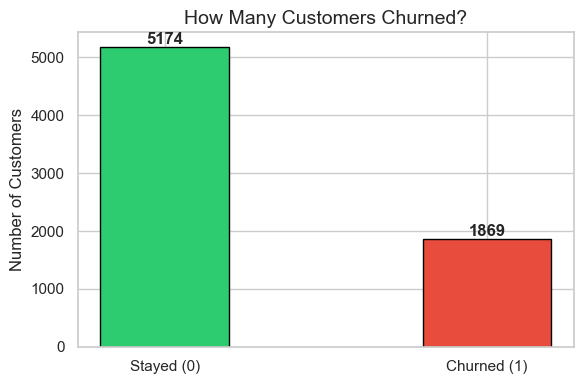

Stayed  : 5,174 (73.5%)
Churned  : 1,869 (26.5%)


In [13]:
# Univariate Analysis
# Churn Distribution (Target Variable)

# How many customers stayed and how many customers left?

churn_counts = df['Churn'].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(['Stayed (0)', 'Churned (1)'],
        churn_counts.values,
        color = ['#2ecc71', '#e74c3c'],
        edgecolor='black', width=0.4)

# Add the numbers on top of the bar
for i, v in enumerate(churn_counts.values):
    plt.text(i, v+50, str(v), ha='center', fontweight='bold')

plt.title('How Many Customers Churned?', fontsize=14)
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

print(f"Stayed  : {churn_counts[0]:,} ({churn_counts[0]/len(df)*100:.1f}%)")
print(f"Churned  : {churn_counts[1]:,} ({churn_counts[1]/len(df)*100:.1f}%)")

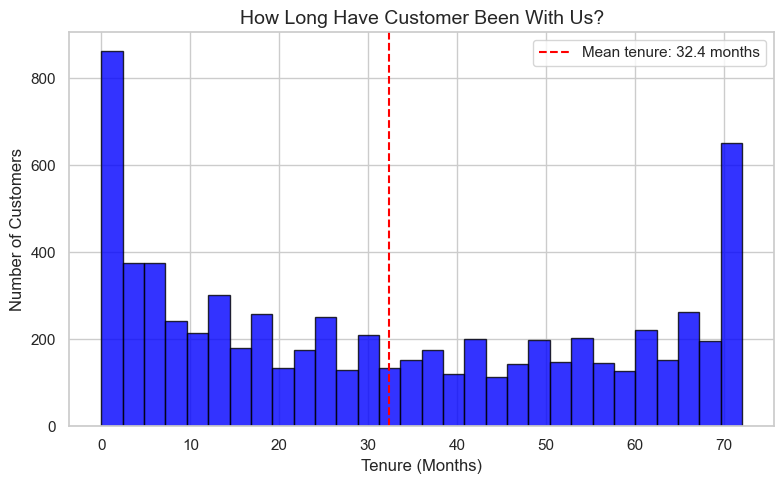

Shortest tenure : 0 months
Average tenure : 32.4 months
Longest tenure : 72 months


In [14]:
# How long have customers stayed with us
# Distribution of Tenure

plt.figure(figsize=(8, 5))
plt.hist(df['tenure'], bins=30, color='blue', edgecolor = 'black', alpha=0.8)

plt.axvline(df['tenure'].mean(), color='red', linestyle='--', label=f"Mean tenure: {df['tenure'].mean():.1f} months")
plt.title('How Long Have Customer Been With Us?', fontsize=14)
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Shortest tenure : {df['tenure'].min()} months")
print(f"Average tenure : {df['tenure'].mean():.1f} months")
print(f"Longest tenure : {df['tenure'].max()} months")

In [15]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,True,False,False,True,False,False,False,False,True,False
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,True,False,False,False,True,False,False,False,False,True
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,True,False,False,False,True,False,True,False,False,False
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,False,True,False,True,False,False,False,False,True,False


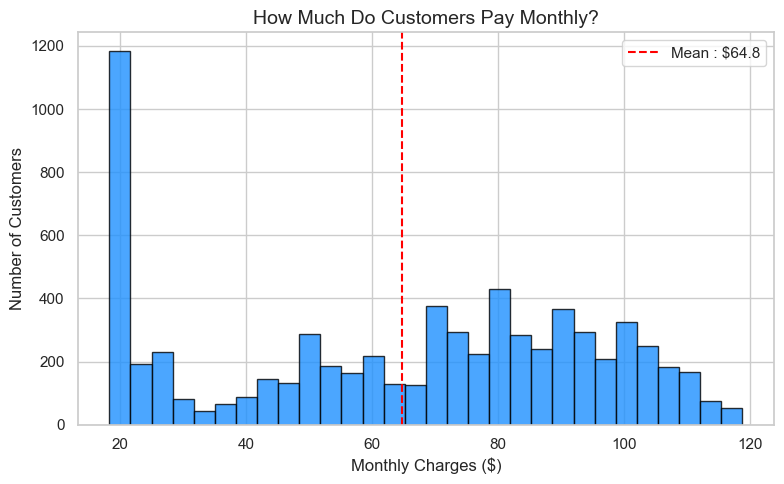

Lowest charge : $18.25
Average charge : $64.76
Highest charge : $118.75


In [16]:
# How much do customers pay monthly
# Distribution of MonthlyCharges

plt.figure(figsize=(8, 5))
plt.hist(df['MonthlyCharges'], bins=30, color='dodgerblue', edgecolor = 'black', alpha=0.8)

plt.axvline(df['MonthlyCharges'].mean(), color='red', linestyle='--', label=f"Mean : ${df['MonthlyCharges'].mean():.1f}")
plt.title('How Much Do Customers Pay Monthly?', fontsize=14)
plt.xlabel('Monthly Charges ($)')
plt.ylabel('Number of Customers')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Lowest charge : ${df['MonthlyCharges'].min()}")
print(f"Average charge : ${df['MonthlyCharges'].mean():.2f}")
print(f"Highest charge : ${df['MonthlyCharges'].max()}")

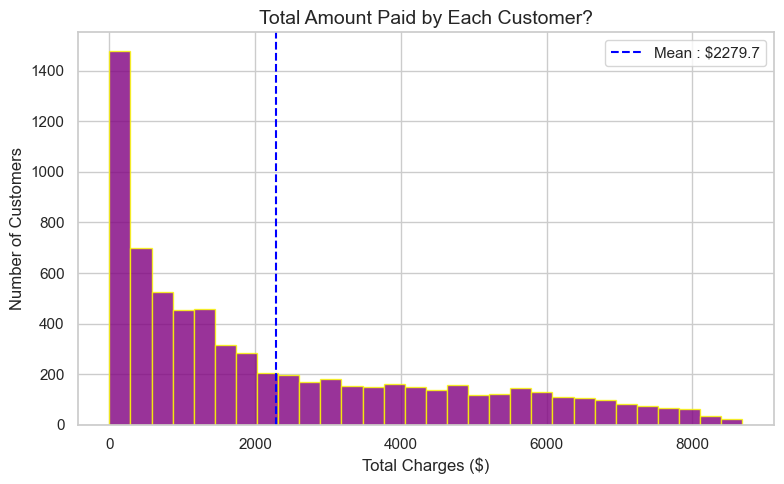

Lowest total : $0.0
Average total : $2279.73
Highest total : $8684.8


In [17]:
# Total Amount Paid by Each Customer
# Distribution of Total Charges

plt.figure(figsize=(8, 5))
plt.hist(df['TotalCharges'], bins=30, color='purple', edgecolor = 'yellow', alpha=0.8)

plt.axvline(df['TotalCharges'].mean(), color='blue', linestyle='--', label=f"Mean : ${df['TotalCharges'].mean():.1f}")
plt.title('Total Amount Paid by Each Customer?', fontsize=14)
plt.xlabel('Total Charges ($)')
plt.ylabel('Number of Customers')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Lowest total : ${df['TotalCharges'].min()}")
print(f"Average total : ${df['TotalCharges'].mean():.2f}")
print(f"Highest total : ${df['TotalCharges'].max()}")

#### Bivariate Analysis


<Figure size 700x500 with 0 Axes>

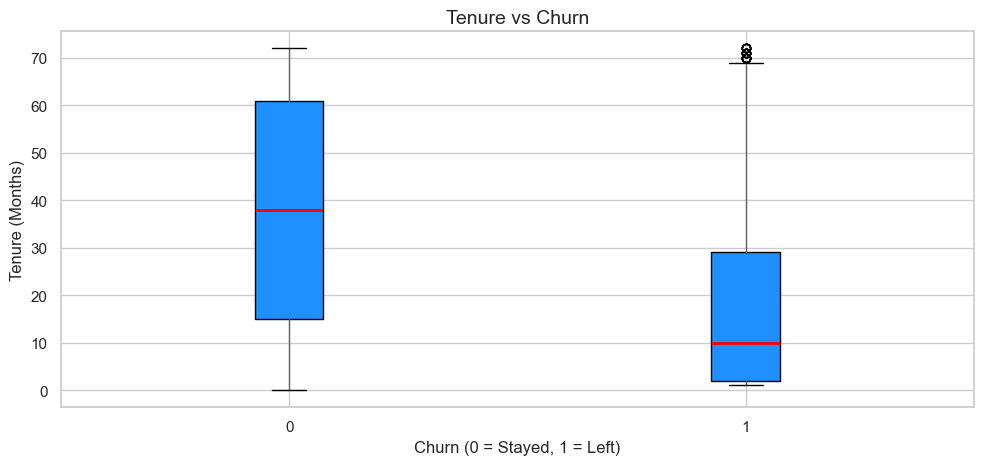

Average tenure by Churn status:
Churn
0   37.60
1   18.00
Name: tenure, dtype: float64


In [18]:
# Tenure vs Churn
# "Are new customers the ones churning the most?"
# "How long do churners stay before they leave"

plt.figure(figsize=(7, 5))
df.boxplot(column='tenure', by='Churn',
           patch_artist=True,
           boxprops=dict(facecolor='dodgerblue', color='black'),
           medianprops=dict(color='red', linewidth=2))

plt.title('Tenure vs Churn', fontsize=14)
plt.suptitle('')
plt.xlabel('Churn (0 = Stayed, 1 = Left)')
plt.ylabel('Tenure (Months)')
plt.tight_layout()
plt.show()

# Print average tenure for each group
print("Average tenure by Churn status:")
print(df.groupby('Churn')['tenure'].mean().round(1))

> ##### Feedback: "Tenure Vs Churn"
> ##### "Most Customers leave early. Say within the first 10 months"

<Figure size 700x500 with 0 Axes>

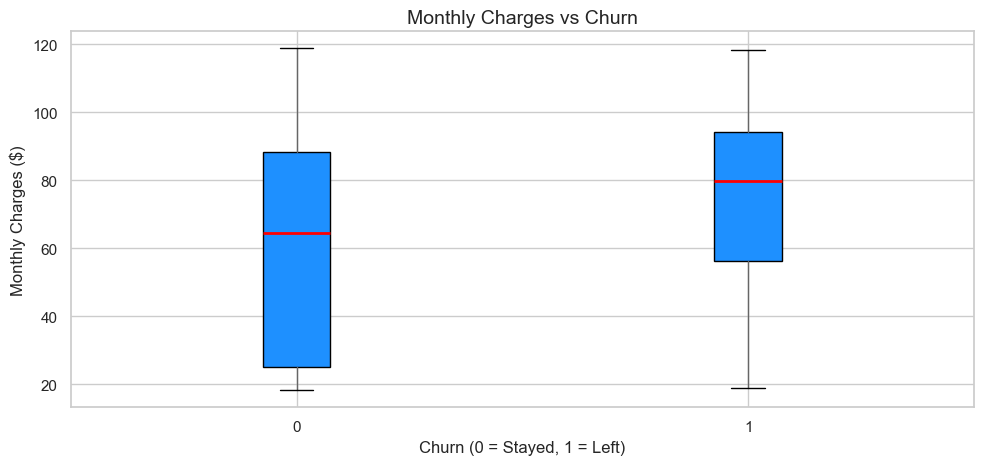

Average Monthly Charges by Churn status:
Churn
0   61.27
1   74.44
Name: MonthlyCharges, dtype: float64


In [19]:
# Monthly Charges Vs Churn
# "Do customers who pay more churn more"

plt.figure(figsize=(7, 5))
df.boxplot(column='MonthlyCharges', by='Churn',
           patch_artist=True,
           boxprops=dict(facecolor='dodgerblue', color='black'),
           medianprops=dict(color='red', linewidth=2))

plt.title('Monthly Charges vs Churn', fontsize=14)
plt.suptitle('')
plt.xlabel('Churn (0 = Stayed, 1 = Left)')
plt.ylabel('Monthly Charges ($)')
plt.tight_layout()
plt.show()

# Print average tenure for each group
print("Average Monthly Charges by Churn status:")
print(df.groupby('Churn')['MonthlyCharges'].mean().round(2))

> ##### Feedback: "Monthly Charges Vs Churn"
> ##### "Higher Charges = Higher Churn Risk"

In [20]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,True,False,False,True,False,False,False,False,True,False
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,True,False,False,False,True,False,False,False,False,True
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,True,False,False,False,True,False,True,False,False,False
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,False,True,False,True,False,False,False,False,True,False


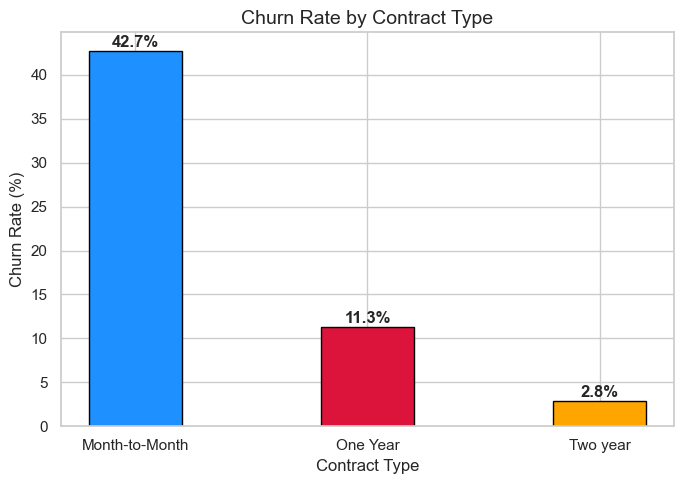

In [21]:
# Contract Type Vs Churn
# "Does the type of contract affect churn?"

# Calculate churn rate by contract type
contarct_churn = df.groupby([
    'Contract_Month-to-month',
    'Contract_One year',
    'Contract_Two year'
])['Churn'].mean() * 100

df['Contract_Type'] = 'Month-to-Month'
df.loc[df['Contract_One year'] == 1, 'Contract_Type'] = 'One Year'
df.loc[df['Contract_Two year'] == 1, 'Contract_Type'] = 'Two year'

churn_by_contract = df.groupby('Contract_Type')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))
bars = plt.bar(churn_by_contract.index,
               churn_by_contract.values,
               color=['dodgerblue', 'crimson', 'orange'],
               edgecolor='black', width=0.4)

# Add percentage labels on bars
for bar, val in zip(bars, churn_by_contract.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.5,
             f'{val:.1f}%', ha='center', fontweight='bold')

plt.title('Churn Rate by Contract Type', fontsize=14)
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

> ##### Feedback: "Contract Type Vs Churn"
> ##### Absolutely! Shorter contract tenure means zero commitment, hence, its easy to leave.

In [22]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_Type
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,True,False,False,True,False,False,False,False,True,False,Month-to-Month
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,True,False,False,False,True,False,False,False,False,True,One Year
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,Month-to-Month
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,True,False,False,False,True,False,True,False,False,False,One Year
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,False,True,False,True,False,False,False,False,True,False,Month-to-Month


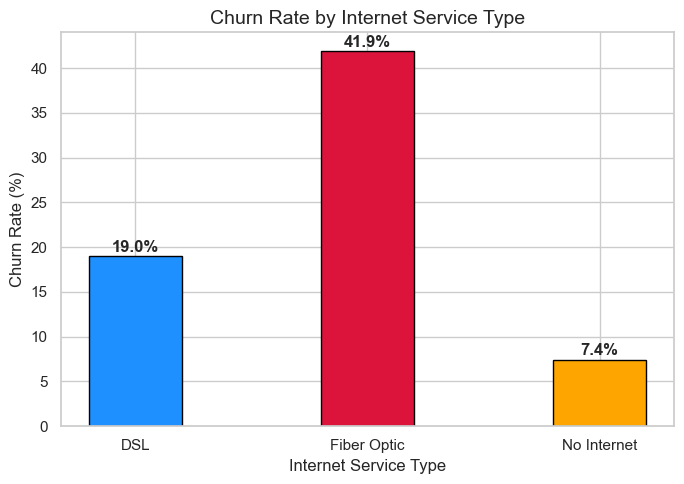

Churn Rate by Internet Service:
Internet_Type
DSL           19.00
Fiber Optic   41.90
No Internet    7.40
Name: Churn, dtype: float64


In [23]:
# Internet Service Vs Churn
# "Does the type of internet service affect churn?"

# rebuild internet service column for plotting
df['Internet_Type'] = "No Internet"
df.loc[df['InternetService_DSL'] == 1, 'Internet_Type'] = 'DSL'
df.loc[df['InternetService_Fiber optic'] == 1, "Internet_Type"] = 'Fiber Optic'

churn_by_internet = df.groupby('Internet_Type')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))
bars = plt.bar(churn_by_internet.index,
               churn_by_internet.values,
               color=['dodgerblue', 'crimson', 'orange'],
               edgecolor='black', width=0.4)

# Add percentage labels on bars
for bar, val in zip(bars, churn_by_internet.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.5,
             f'{val:.1f}%', ha='center', fontweight='bold')

plt.title('Churn Rate by Internet Service Type', fontsize=14)
plt.xlabel("Internet Service Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

print("Churn Rate by Internet Service:")
print(churn_by_internet.round(1))

> #### Feedback: Internet Service Vs Churn
> #### Yes! Fiber optic is a strong indicator for churn.

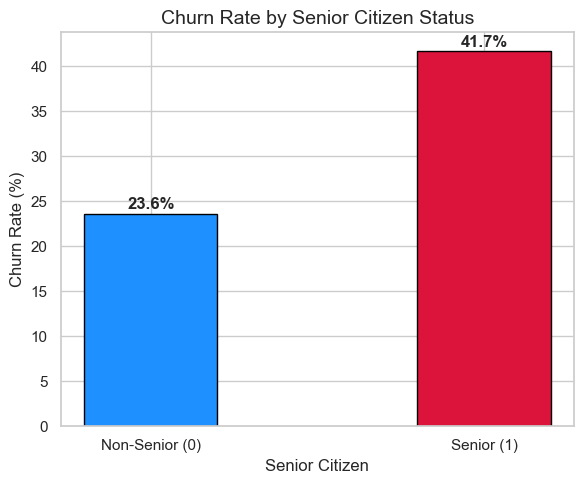

Churn Rate by Senior Citizen Status:
SeniorCitizen
0   23.60
1   41.70
Name: Churn, dtype: float64

Customer Count by Senior Citizen Status:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


In [24]:
# Senior Citizen Vs Churn
# "Do senior citizens churn more than non-senior citizens"

churn_by_senior = df.groupby('SeniorCitizen')['Churn'].mean() * 100

plt.figure(figsize=(6, 5))
bars = plt.bar(['Non-Senior (0)', 'Senior (1)'],
               churn_by_senior.values,
               color=['dodgerblue', 'crimson'],
               edgecolor='black', width=0.4)

# Add percentage labels on bars
for bar, val in zip(bars, churn_by_senior.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.5,
             f'{val:.1f}%', ha='center', fontweight='bold')

plt.title('Churn Rate by Senior Citizen Status', fontsize=14)
plt.xlabel("Senior Citizen")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

print("Churn Rate by Senior Citizen Status:")
print(churn_by_senior.round(1))

print("\nCustomer Count by Senior Citizen Status:")
print(df['SeniorCitizen'].value_counts())

> #### Feedback: Senior Citizen Vs Churn
> #### "Senior Citizen are more likely to leave"

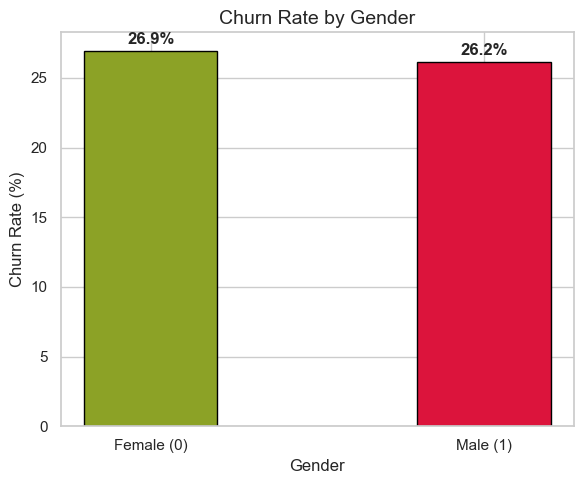

Churn Rate by Gender:
gender
0   26.90
1   26.20
Name: Churn, dtype: float64


In [25]:
# Gender Vs Churn
# "Does gender affects whether a customer churns"

churn_by_gender = df.groupby('gender')['Churn'].mean() * 100

plt.figure(figsize=(6, 5))
bars = plt.bar(['Female (0)', 'Male (1)'],
               churn_by_gender.values,
               color=["#8CA226", 'crimson'],
               edgecolor='black', width=0.4)

# Add percentage labels on bars
for bar, val in zip(bars, churn_by_gender.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.5,
             f'{val:.1f}%', ha='center', fontweight='bold')

plt.title('Churn Rate by Gender', fontsize=14)
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

print("Churn Rate by Gender:")
print(churn_by_gender.round(1))

> #### Feedback: Gender Vs Chrun
> #### Virtually no difference at all. 0.7% separates females from males. Gender is not a useful indicator of churn.

> #### Bivariate Analysis Summary:
> ##### Contract Type (Very strong indicator for churn)
> ##### Fibre Optic(Internet Service) - (Very strong indicator for churn)
> ##### Tenure (Very strong indicator for churn)
> ##### Senior Citizen (Useful indicator for churn)
> ##### Monthly Charges (Useful indicator for churn)
> ##### Gender (Not an important indicator for churn)

#### Multivariate Analysis

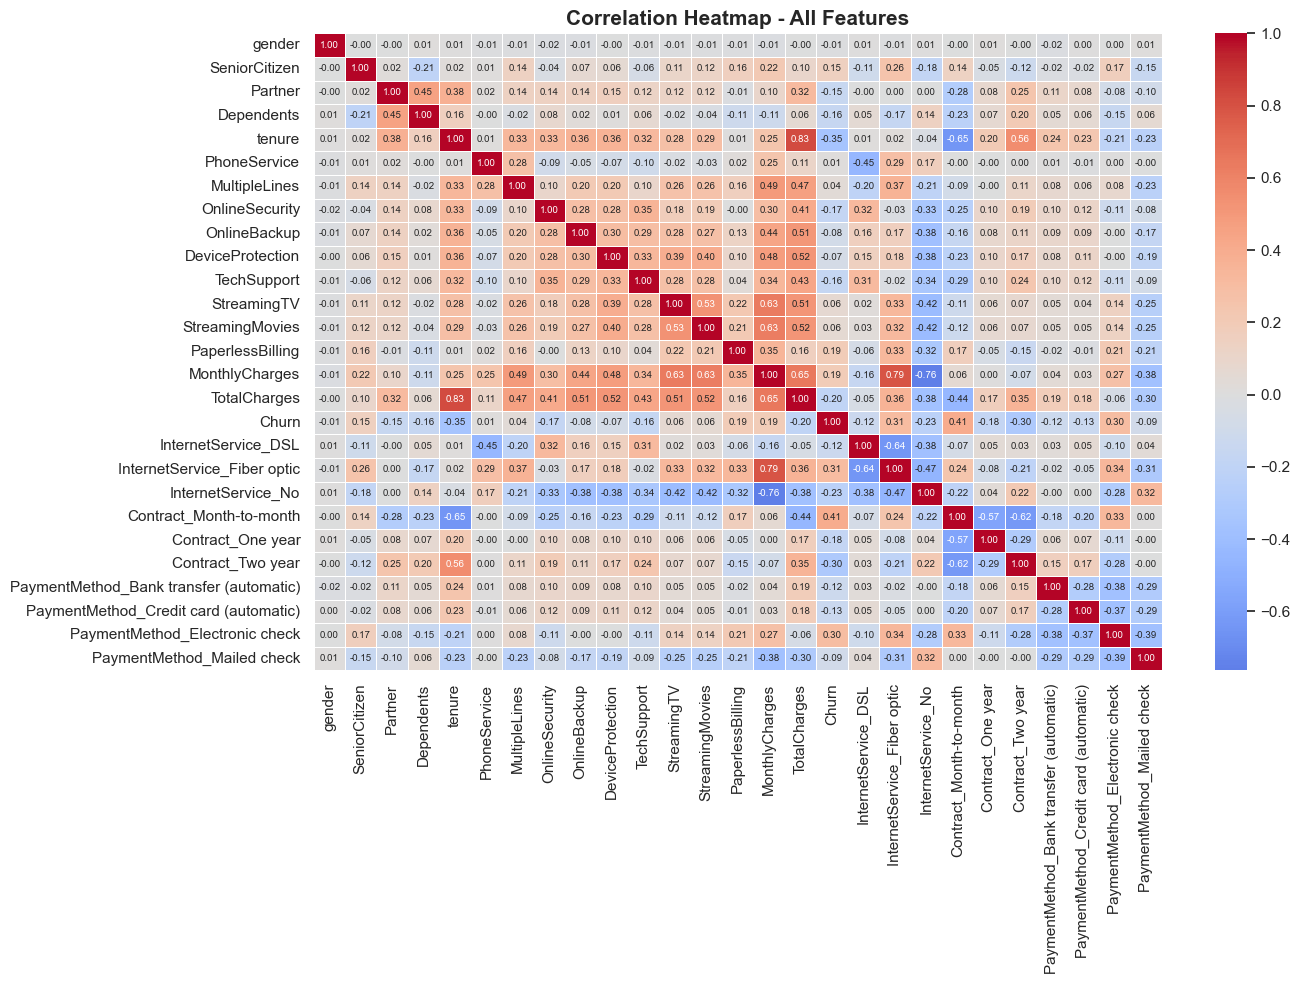

Correlation with Churn (ranked):
Churn                                      1.00
Contract_Month-to-month                    0.41
InternetService_Fiber optic                0.31
PaymentMethod_Electronic check             0.30
MonthlyCharges                             0.19
PaperlessBilling                           0.19
SeniorCitizen                              0.15
StreamingTV                                0.06
StreamingMovies                            0.06
MultipleLines                              0.04
PhoneService                               0.01
gender                                    -0.01
DeviceProtection                          -0.07
OnlineBackup                              -0.08
PaymentMethod_Mailed check                -0.09
PaymentMethod_Bank transfer (automatic)   -0.12
InternetService_DSL                       -0.12
PaymentMethod_Credit card (automatic)     -0.13
Partner                                   -0.15
Dependents                                -0.16
TechSup

In [26]:
# Multivariate Analysis - Comparing more than two variables
# "How do all our features affect or relate to CHURN?"
# Correlation Heatmap

# Drop the temporary columns we created for plotting
df_corr = df.drop(columns=['Contract_Type',
                           'Internet_Type'], errors='ignore')

plt.figure(figsize=(14, 10))
corr_matrix = df_corr.corr()

sns.heatmap(corr_matrix,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            linewidth=0.5,
            annot_kws={'size': 7})

plt.title('Correlation Heatmap - All Features',
          fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# Print the Churn correlation ranks
print("Correlation with Churn (ranked):")
print(corr_matrix['Churn'].sort_values(ascending=False).round(2))

#### Feature Engineering

In [27]:
# Vertical Split: Feature Matrix (X) and Target Variable (y)

# Drop temporary plotting columns and target to get X
X = df.drop(columns=['Churn', 'Contract_Type', 'Internet_Type'], errors='ignore')

# Target variable
y = df['Churn']

print(f"Features Shape (X): {X.shape}")
print(f"Target Shape (y): {y.shape}")
print(f"\nFeature columns ({len(X.columns)}):")
for col in X.columns:
    print(f"    -> {col}")
print(f"Target Distribution:")
print(y.value_counts())

Features Shape (X): (7043, 26)
Target Shape (y): (7043,)

Feature columns (26):
    -> gender
    -> SeniorCitizen
    -> Partner
    -> Dependents
    -> tenure
    -> PhoneService
    -> MultipleLines
    -> OnlineSecurity
    -> OnlineBackup
    -> DeviceProtection
    -> TechSupport
    -> StreamingTV
    -> StreamingMovies
    -> PaperlessBilling
    -> MonthlyCharges
    -> TotalCharges
    -> InternetService_DSL
    -> InternetService_Fiber optic
    -> InternetService_No
    -> Contract_Month-to-month
    -> Contract_One year
    -> Contract_Two year
    -> PaymentMethod_Bank transfer (automatic)
    -> PaymentMethod_Credit card (automatic)
    -> PaymentMethod_Electronic check
    -> PaymentMethod_Mailed check
Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [28]:
# Horizontal Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Split complete!")
print(f"\nTraining Set : {X_train.shape[0]} customers (80%)")
print(f"Test Set : {X_test.shape[0]} customers (20%)")
print(f"\nChurn rate in training set: {y_train.mean()*100:.1f}%")
print(f"Churn rate in test set: {y_test.mean()*100:.1f}%")

Split complete!

Training Set : 5634 customers (80%)
Test Set : 1409 customers (20%)

Churn rate in training set: 26.5%
Churn rate in test set: 26.5%


In [29]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_Type,Internet_Type
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,True,False,False,True,False,False,False,False,True,False,Month-to-Month,DSL
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,True,False,False,False,True,False,False,False,False,True,One Year,DSL
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,Month-to-Month,DSL
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,True,False,False,False,True,False,True,False,False,False,One Year,DSL
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,False,True,False,True,False,False,False,False,True,False,Month-to-Month,Fiber Optic


In [30]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
gender,7043.00,0.50,0.50,0.00,0.00,1.00,1.00,1.00
SeniorCitizen,7043.00,0.16,0.37,0.00,0.00,0.00,0.00,1.00
Partner,7043.00,0.48,0.50,0.00,0.00,0.00,1.00,1.00
Dependents,7043.00,0.30,0.46,0.00,0.00,0.00,1.00,1.00
tenure,7043.00,32.37,24.56,0.00,9.00,29.00,55.00,72.00
PhoneService,7043.00,0.90,0.30,0.00,1.00,1.00,1.00,1.00
MultipleLines,7043.00,0.42,0.49,0.00,0.00,0.00,1.00,1.00
OnlineSecurity,7043.00,0.29,0.45,0.00,0.00,0.00,1.00,1.00
OnlineBackup,7043.00,0.34,0.48,0.00,0.00,0.00,1.00,1.00
DeviceProtection,7043.00,0.34,0.48,0.00,0.00,0.00,1.00,1.00


In [31]:
# Scaling Numeric Columns Using Standard Scaler
# z = (value-mean)/standard deviation

scaler = StandardScaler()

# Column to scale
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Fit ONLY on training set, transform both (Training and Testing)
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print('Scaling Complete!')
print(X_train[numeric_cols].describe().round(2))

Scaling Complete!
       tenure  MonthlyCharges  TotalCharges
count 5634.00         5634.00       5634.00
mean    -0.00           -0.00          0.00
std      1.00            1.00          1.00
min     -1.32           -1.54         -1.01
25%     -0.96           -0.97         -0.83
50%     -0.14            0.18         -0.40
75%      0.92            0.83          0.67
max      1.61            1.79          2.80


In [32]:
"""
From our univariate analysis of our target variable (Churn), we have a class imbalance
Stayed  : 5,174 (73.5%)
Churned  : 1,869 (26.5%)
"""

# Fixing class imbalance using SMOTE
# We are applying SMOTE to just our training dataset

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('SMOTE Applied!')
print(f"\nBefore SMOTE:")
print(f"    No Churn : {sum(y_train == 0):,}")
print(f"    Churn : {sum(y_train == 1):,}")
print(f"\nAfter SMOTE:")
print(f"    No Churn : {sum(y_train_sm == 0):,}")
print(f"    Churn : {sum(y_train_sm == 1):,}")
print(f"\nNew training set size: {X_train_sm.shape[0]:,} customers")

SMOTE Applied!

Before SMOTE:
    No Churn : 4,139
    Churn : 1,495

After SMOTE:
    No Churn : 4,139
    Churn : 4,139

New training set size: 8,278 customers


#### PHASE 5 - **MACHINE LEARNING MODELLING**

In [33]:
# Logistic Regression
# We will use Logistic Regression as our baseline

# Build and Train the model

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_sm, y_train_sm)

# Make predictions on test set
lr_preds = lr_model.predict(X_test)
lr_proba = lr_model.predict_proba(X_test)[:, 1]

# Evaluate
print("=" * 50)
print(" MODEL 1 - LOGISTIC REGRESSION RESULTS")
print("=" * 50)
print(classification_report(y_test, lr_preds, target_names=['No Churn', 'Churn']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, lr_proba):.4f}")

 MODEL 1 - LOGISTIC REGRESSION RESULTS
              precision    recall  f1-score   support

    No Churn       0.89      0.77      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409

ROC-AUC Score: 0.8356


In [34]:
# Random Forest

# Build and train the model
rf_model = RandomForestClassifier(n_estimators=100,
                                  random_state=42)
rf_model.fit(X_train_sm, y_train_sm)

# Make prediction on test set
rf_preds = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

# Evaluate
print("=" * 50)
print(" MODEL 2 - RANDOM FOREST RESULTS")
print("=" * 50)
print(classification_report(y_test, rf_preds, target_names=['No Churn', 'Churn']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_proba):.4f}")

 MODEL 2 - RANDOM FOREST RESULTS
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.56      0.64      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409

ROC-AUC Score: 0.8228


In [35]:
# XGBoost - Extreme Gradient Boosting
# Build and train model

xgb_model = XGBClassifier(n_estimators=100,
                          random_state=42,
                          eval_metric='logloss',
                          verbosity=0)
xgb_model.fit(X_train_sm, y_train_sm)

# Make predictions on test set

xgb_preds = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate
print("=" * 50)
print(" MODEL 3 - XGBOOST RESULTS")
print("=" * 50)
print(classification_report(y_test, xgb_preds, target_names=['No Churn', 'Churn']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, xgb_proba):.4f}")


 MODEL 3 - XGBOOST RESULTS
              precision    recall  f1-score   support

    No Churn       0.87      0.80      0.84      1035
       Churn       0.55      0.68      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409

ROC-AUC Score: 0.8076


#### Phase 6 - **Model Evaluation and Visualization**
#### Confusion Matrix || ROC Curve || Feature Importance || Model Comparison

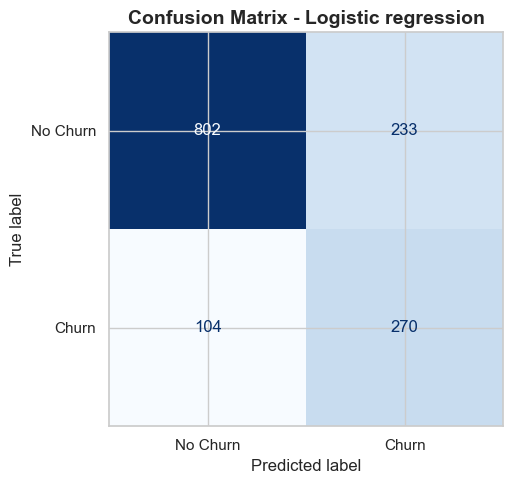

 True Negatives (correctly said stay) : 802
 False positives (wrongly said churn) : 233
 False Negatives (missed churners) : 104
 True Positives (correctly caught churners) : 270

Of 374 actual churners we caught 270 (72.2%)


In [36]:
# Confusion Matrix - Logistic Regression

cm = confusion_matrix(y_test, lr_preds)

fig, ax = plt.subplots(figsize=(7, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
disp.plot(ax=ax, cmap='Blues', colorbar=False)

ax.set_title('Confusion Matrix - Logistic regression',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Break down the numbers
tn, fp, fn, tp = cm.ravel()
print(f" True Negatives (correctly said stay) : {tn}")
print(f" False positives (wrongly said churn) : {fp}")
print(f" False Negatives (missed churners) : {fn}")
print(f" True Positives (correctly caught churners) : {tp}")
print(f"\nOf {tp+fn} actual churners we caught {tp} ({tp/(tp+fn) * 100:.1f}%)")

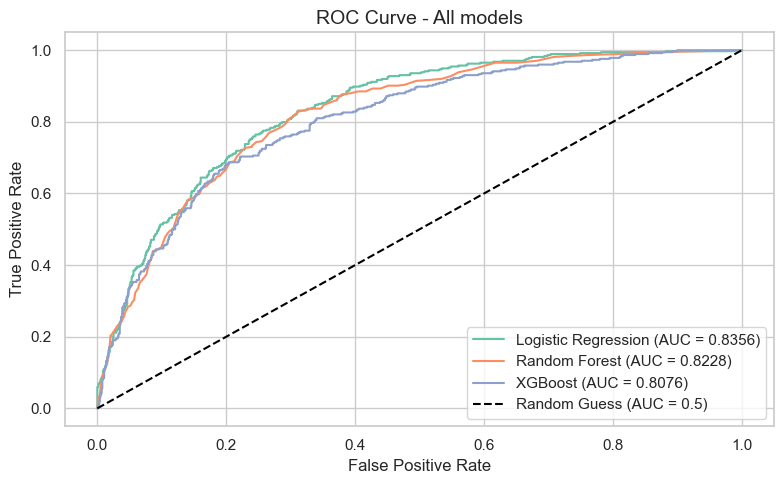

In [37]:
# ROC Curve - All 3 Model

plt.figure(figsize=(8, 5))

# Plot all 3 models
for name, proba in [('Logistic Regression', lr_proba),
                    ('Random Forest', rf_proba),
                    ('XGBoost', xgb_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

# Eandom guess baseline
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5)')

plt.title('ROC Curve - All models', fontsize=14)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()
plt.show()


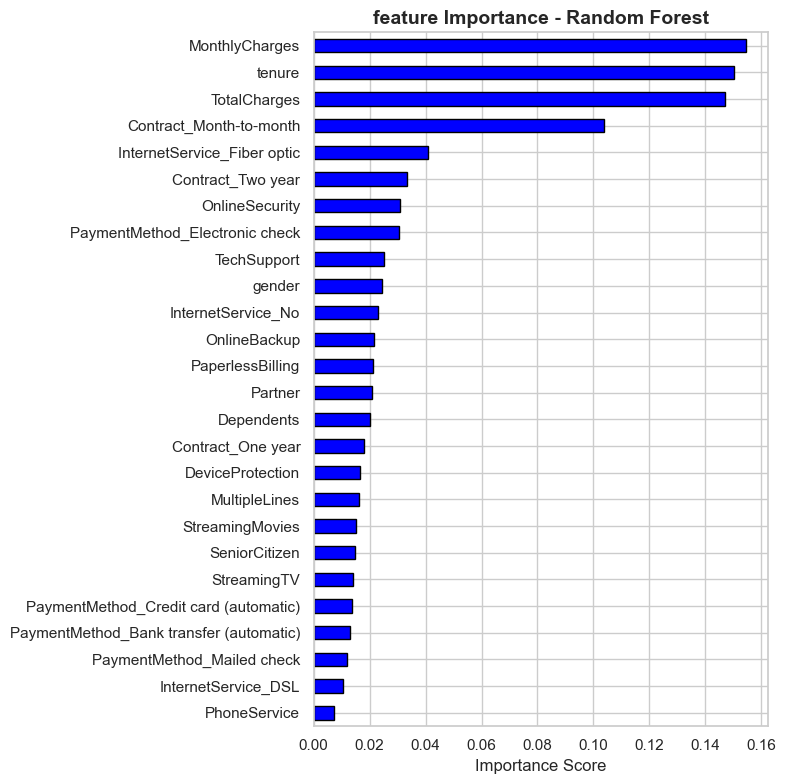

top 5 Most Important Features:
MonthlyCharges                0.15
tenure                        0.15
TotalCharges                  0.15
Contract_Month-to-month       0.10
InternetService_Fiber optic   0.04
dtype: float64


In [39]:
# Feature Importance - Random Forest

importances = pd.Series(rf_model.feature_importances_,
                        index=X.columns)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(8, 8))
importances.plot(kind='barh', color='blue', edgecolor='black')

plt.title('feature Importance - Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print("top 5 Most Important Features:")
print(importances.sort_values(ascending=False).head())

In [40]:
# SAVE MODEL
import joblib

joblib.dump(lr_model, 'churn_model_2.pkl')
joblib.dump(scaler, 'churn_scaler.pkl')
joblib.dump(list(X.columns), 'feature_columns.pkl')


['feature_columns.pkl']